# ***Question: Predict a score for the team.***

#**Dataset Loaded**

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
dataset = pd.read_csv("t20_cricket_match_score_prediction.csv")
dataset.head(5)

,Match ID,Overs Played,Wickets Lost,Run Rate,Home/Away,Opponent Strength,Pitch Condition,Weather,Predicted Score
0,1,7,1,11.04,Away,3,Bowling,Sunny,82
1,2,20,10,11.87,Home,5,Bowling,Sunny,204
2,3,15,7,6.14,Home,7,Balanced,Sunny,105
3,4,11,8,8.84,Home,9,Batting,Cloudy,121
4,5,8,0,9.56,Home,2,Balanced,Sunny,104


#Check imbalance in data not possible because it's a regression problem and too many unique values


In [38]:
dataset['Predicted Score'].unique()



array([ 82, 204, 105, 121, 104,  55, 125,  92, 159,  31,  44,  37,  48,
       133,  80,  43,  18,  85, 158, 218, 115, 212, 209, 132, 232,  65,
       172,  34,  45, 207,  73,  69, 106, 130,  42, 131, 182, 340, 234,
        72,  38, 279,  70, 301, 108,  39,  36,  93,  91,  61, 190, 150,
        35,  60, 201, 164,  54,  74, 193,  88, 140, 188,  83, 138, 179,
       134,  66,  76, 281,  67,  21,  20,  32,  58, 128, 151, 152,  23,
        28,  64,  46,  52, 107, 169,  50,  15, 102, 114,  96, 119,  81,
        75, 141, 112, 194,  71, 167, 117, 222, 174,  77, 168,  27, 101,
        79, 356,  29, 110, 220,  24, 248,  78, 186, 149, 233, 236, 254,
       250,  25,  22,  14, 285, 176,  56,  98, 211,  49, 272,  59,  86,
        87, 181, 278, 309, 227,  84, 288,  57, 241,  53,  33, 185,  12,
       200, 165,  51,  97, 192,  16, 217, 214, 142, 267, 144,  41, 229,
       197, 154, 100,  90,  26, 126, 202, 178, 170, 146,  68,  30, 252,
        62, 175, 230, 171, 137,  19, 111, 205, 173, 161, 180, 15

#Histogram to see the output distribution

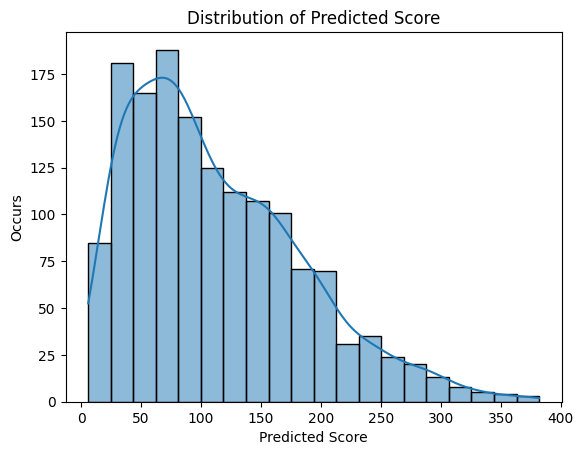


0.8779948025045805


In [39]:
sns.histplot(dataset['Predicted Score'], bins=20,kde=True )
plt.xlabel("Predicted Score")
plt.ylabel("Occurs")
plt.title("Distribution of Predicted Score")
plt.show()
print()
print(dataset['Predicted Score'].skew()) #rightside moderately skewed


#**EDA**

In [40]:
##Dataset Features
dataset.info()
dataset.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Match ID           1500 non-null   int64  
 1   Overs Played       1500 non-null   int64  
 2   Wickets Lost       1500 non-null   int64  
 3   Run Rate           1500 non-null   float64
 4   Home/Away          1500 non-null   object 
 5   Opponent Strength  1500 non-null   int64  
 6   Pitch Condition    1500 non-null   object 
 7   Weather            1500 non-null   object 
 8   Predicted Score    1500 non-null   int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 105.6+ KB


,Match ID,Overs Played,Wickets Lost,Run Rate,Opponent Strength,Predicted Score
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,10.255333,4.894000,9.964173,5.499333,112.637333
std,433.157015,5.864219,3.078487,2.880189,2.891293,71.886356
min,1.000000,1.000000,0.000000,5.000000,1.000000,6.000000
25%,375.750000,5.000000,2.000000,7.507500,3.000000,56.000000
50%,750.500000,10.000000,5.000000,9.915000,6.000000,97.000000
75%,1125.250000,15.000000,8.000000,12.480000,8.000000,157.000000
max,1500.000000,20.000000,10.000000,15.000000,10.000000,382.000000


In [41]:
#check Null
dataset.isnull().sum()

,0
Match ID,0
Overs Played,0
Wickets Lost,0
Run Rate,0
Home/Away,0
Opponent Strength,0
Pitch Condition,0
Weather,0
Predicted Score,0


Index(['Match ID', 'Overs Played', 'Wickets Lost', 'Run Rate',
       'Opponent Strength', 'Predicted Score'],
      dtype='object')
Index(['Home/Away', 'Pitch Condition', 'Weather'], dtype='object')
Numeric Columns:
 Index(['Match ID', 'Overs Played', 'Wickets Lost', 'Run Rate',
       'Opponent Strength', 'Predicted Score'],
      dtype='object')

Categorical Columns:
 Index(['Home/Away', 'Pitch Condition', 'Weather'], dtype='object')


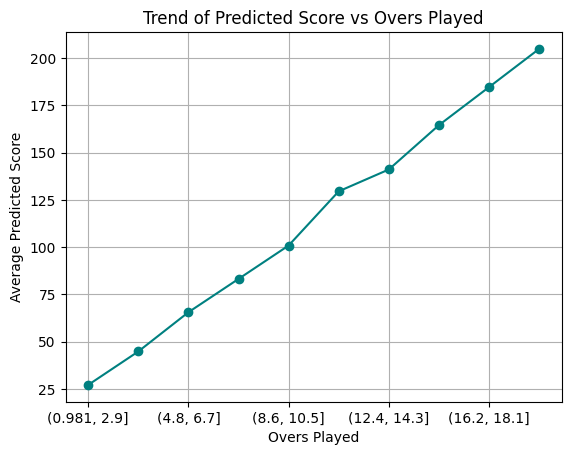

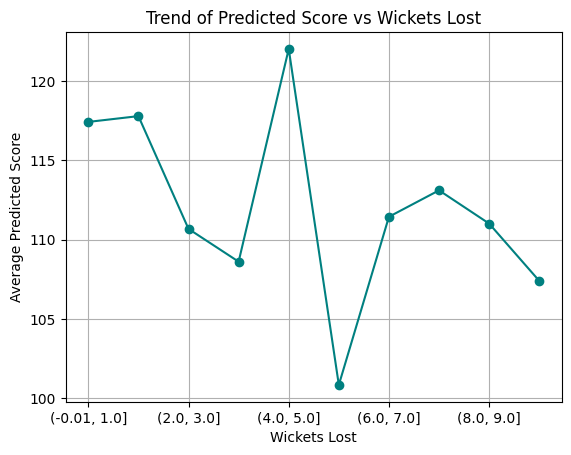

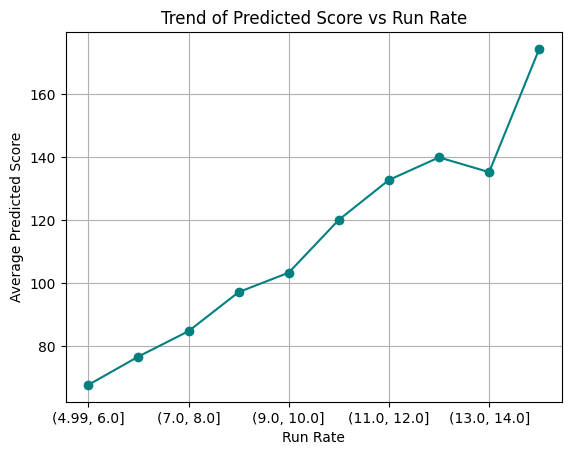

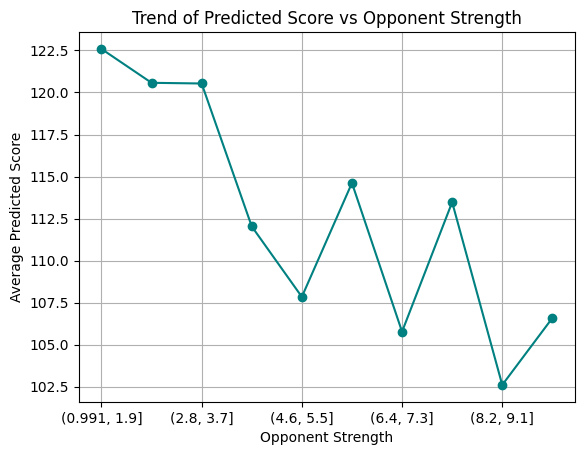

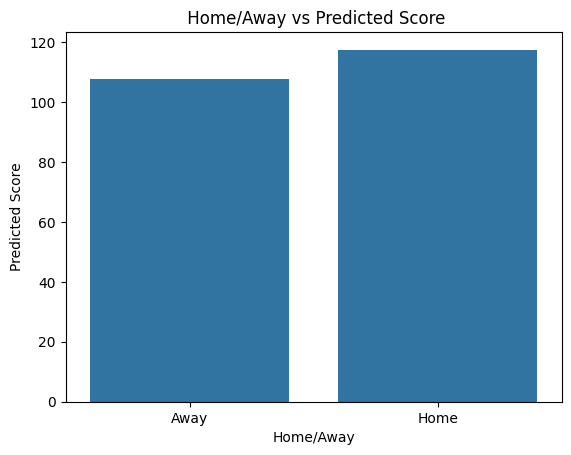

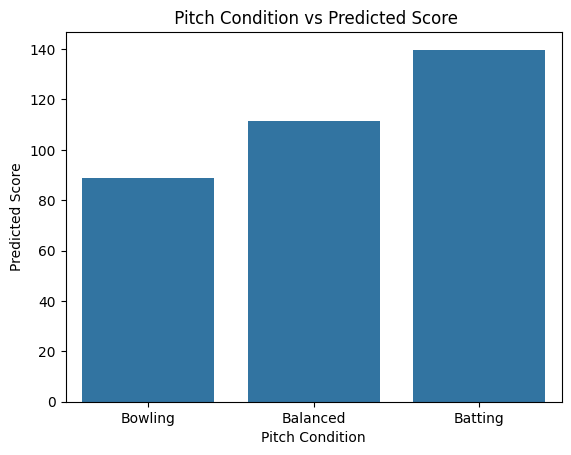

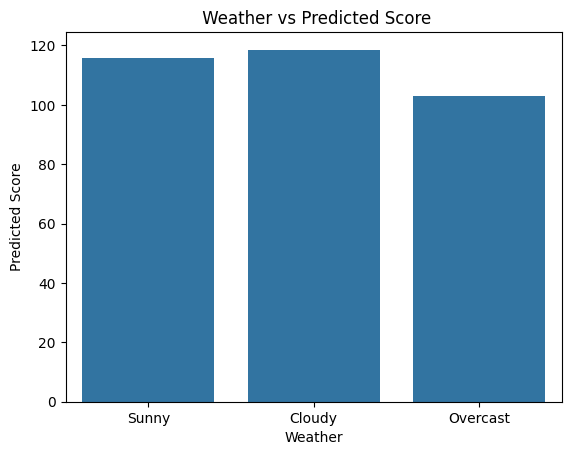

In [42]:
#Analyze numerical and categorical columns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns
print(numeric_cols)
categorical_cols = dataset.select_dtypes(include=['object']).columns
print(categorical_cols)
print("Numeric Columns:\n", numeric_cols)
print("\nCategorical Columns:\n", categorical_cols)

for i in numeric_cols:
    if i !='Predicted Score' and i!='Match ID':
        avg = dataset.groupby(pd.cut(dataset[i], bins=10),observed=False)['Predicted Score'].mean()
        avg.plot(kind='line', marker='o', color='teal')
        plt.title(f"Trend of Predicted Score vs {i}")
        plt.xlabel(i)
        plt.ylabel("Average Predicted Score")
        plt.grid(True)
        plt.show()

for i in categorical_cols:
    sns.barplot(x=i,y='Predicted Score',data=dataset,estimator=np.mean,errorbar=None)
    plt.title(f" {i} vs Predicted Score")
    plt.show()



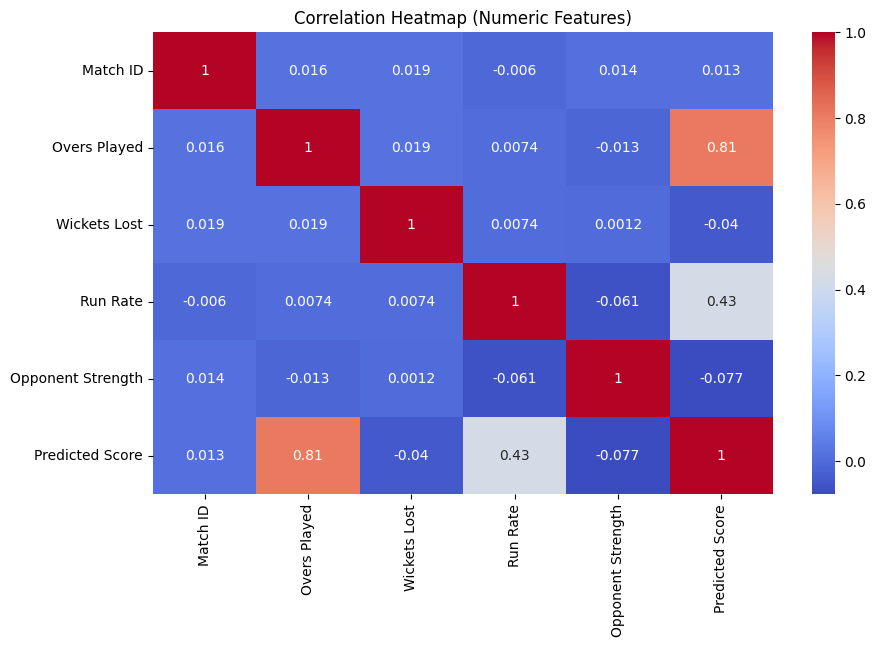

In [43]:
#Creating heatmap for numerical columns
plt.figure(figsize=(10,6))
sns.heatmap(dataset[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()


#Data Preprocessing

**Data categorizing: One hot encoding**

In [44]:
data_enc = pd.get_dummies(dataset[categorical_cols])
data_enc.head()





,Home/Away_Away,Home/Away_Home,Pitch Condition_Balanced,Pitch Condition_Batting,Pitch Condition_Bowling,Weather_Cloudy,Weather_Overcast,Weather_Sunny
0,True,False,False,False,True,False,False,True
1,False,True,False,False,True,False,False,True
2,False,True,True,False,False,False,False,True
3,False,True,False,True,False,True,False,False
4,False,True,True,False,False,False,False,True


"Home/away" this part is column name, so Home/Away_Away shows the away part and Home/Away_Home shows the home part.

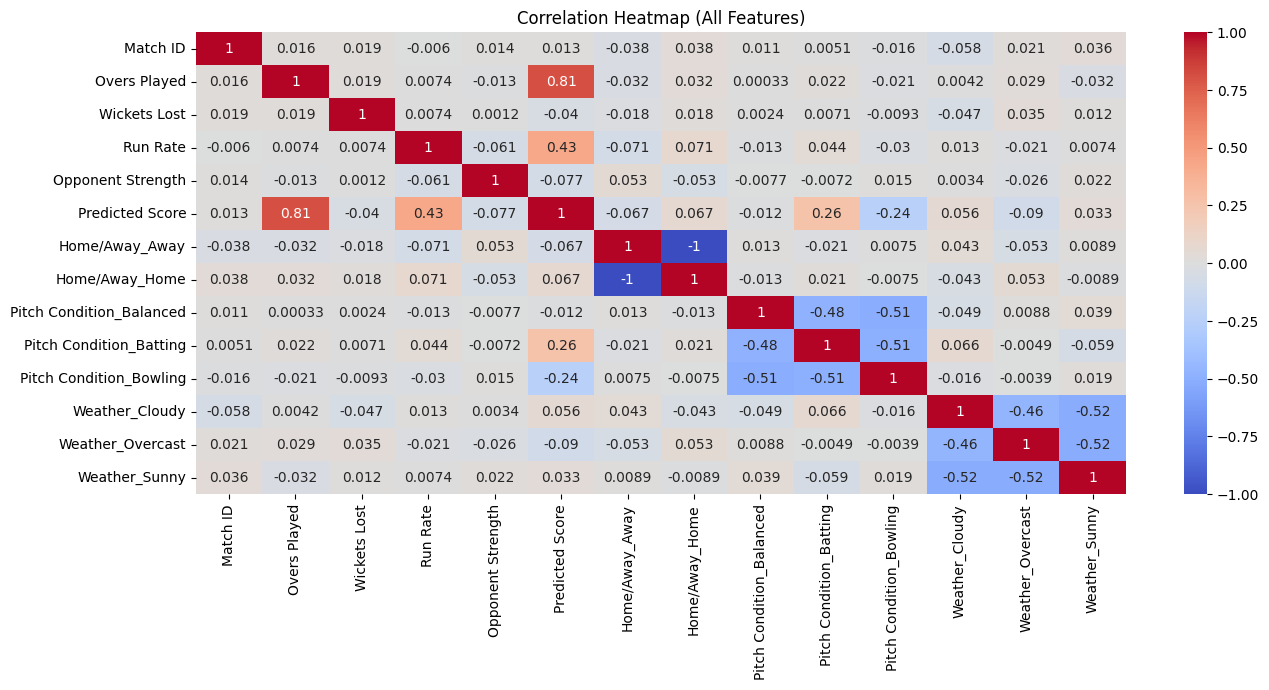

In [45]:
#Creating heatmap for all columns
data_full = dataset.join(data_enc)
data_full=data_full.drop(['Home/Away', 'Pitch Condition', 'Weather'], axis=1)
plt.figure(figsize=(15,6))
sns.heatmap(data_full.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap (All Features)")
plt.show()

#**Feature Scaling**

In [46]:
import sklearn
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
cols_to_scale = [ 'Overs Played','Wickets Lost', 'Run Rate', 'Opponent Strength']
data_full = dataset.join(data_enc)
data_full=data_full.drop(['Home/Away', 'Pitch Condition', 'Weather'], axis=1)
data_full[cols_to_scale] = scaler.fit_transform(data_full[cols_to_scale])
# data_full[cols_to_scale].head()  #to check the coloumns after scaling
# dataset[cols_to_scale].describe()

data_full.head()


,Match ID,Overs Played,Wickets Lost,Run Rate,Opponent Strength,Predicted Score,Home/Away_Away,Home/Away_Home,Pitch Condition_Balanced,Pitch Condition_Batting,Pitch Condition_Bowling,Weather_Cloudy,Weather_Overcast,Weather_Sunny
0,1,0.315789,0.1,0.604,0.222222,82,True,False,False,False,True,False,False,True
1,2,1.000000,1.0,0.687,0.444444,204,False,True,False,False,True,False,False,True
2,3,0.736842,0.7,0.114,0.666667,105,False,True,True,False,False,False,False,True
3,4,0.526316,0.8,0.384,0.888889,121,False,True,False,True,False,True,False,False
4,5,0.368421,0.0,0.456,0.111111,104,False,True,True,False,False,False,False,True


#**Dataset Splitting**

In [47]:
from sklearn.model_selection import train_test_split
X = data_full.drop('Predicted Score', axis=1)  # all other columns
y = data_full['Predicted Score']                # the one we’re predicting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)  # we are using the 42 because It’s just a popular convention used by data scientists. We can use any other number but Not None . If we use NONE it will give diff random values
print("Training set:", X_train.shape, y_train.shape)
print("Testing set:", X_test.shape, y_test.shape)



Training set: (1200, 13) (1200,)
Testing set: (300, 13) (300,)


# Model training & testing

***Linear Regression***

In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
lr_model = LinearRegression()

# train
lr_model.fit(X_train, y_train)
#test
y_pred = lr_model.predict(X_test)


***Decision Tree***

In [49]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np
dt_model = DecisionTreeRegressor()
# train
dt_model.fit(X_train, y_train)
#test
y_pred_dt = dt_model.predict(X_test)


*Neural Network*

In [50]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np


nn_model = MLPRegressor(hidden_layer_sizes=(100,50,),max_iter=1500,random_state=42)

#train
ab=nn_model.fit(X_train, y_train)

#test
y_pred_nn = nn_model.predict(X_test)


# ***Kmeans***

K = 1, SSE = 281253185.70348996
K = 2, SSE = 70315683.20535143
K = 3, SSE = 31253679.15781954
K = 4, SSE = 17582616.705493644
K = 5, SSE = 11254075.061171973
K = 6, SSE = 7817677.061886337
K = 7, SSE = 5743474.970860799
K = 8, SSE = 4401085.458205565
K = 9, SSE = 3476386.8737096987


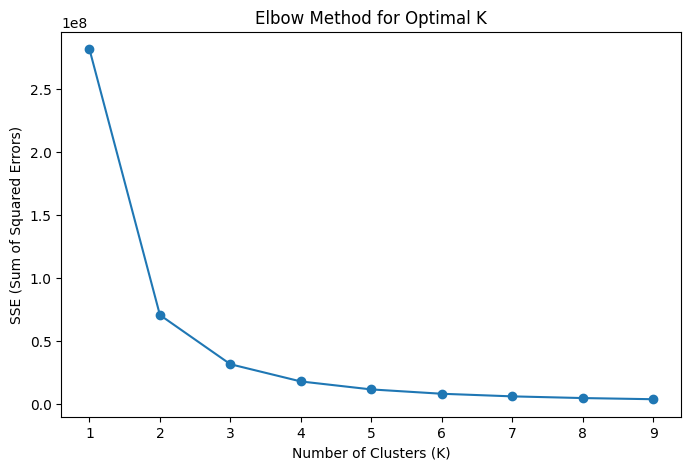

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


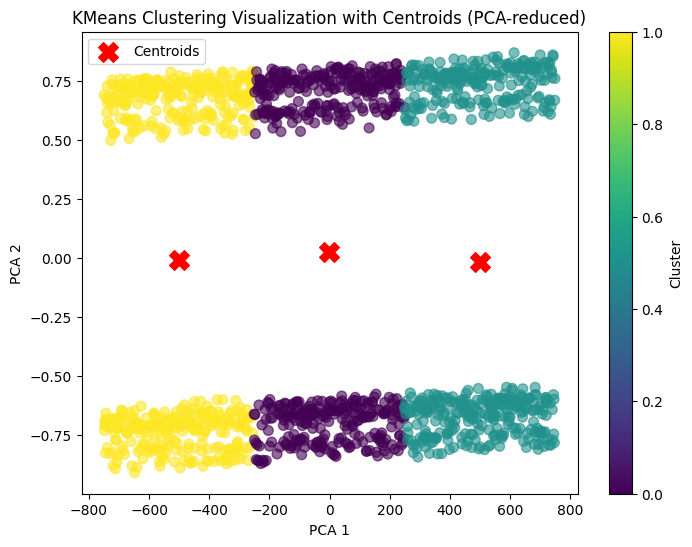

   Predicted Score  Cluster
0               82        2
1              204        2
2              105        2
3              121        2
4              104        2


In [51]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
X_kmeans = X.copy()
sse = []
K_range = range(1, 10)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_kmeans)
    sse.append(km.inertia_)
    print(f"K = {k}, SSE = {km.inertia_}")
plt.figure(figsize=(8,5))
plt.plot(K_range, sse, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("SSE (Sum of Squared Errors)")
plt.title("Elbow Method for Optimal K")
plt.show()

#choosing cluster =3 as  huge drop from 703 to 312

cluster = 3
km = KMeans(n_clusters=cluster, random_state=42, n_init=10)
clusters = km.fit_predict(X_kmeans)


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_kmeans)
centroids_pca = pca.transform(km.cluster_centers_)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="viridis", s=50, alpha=0.6)
plt.scatter(centroids_pca[:,0], centroids_pca[:,1],
            c="red", marker="X", s=200, label="Centroids")
plt.title("KMeans Clustering Visualization with Centroids (PCA-reduced)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster")
plt.legend()
plt.show()
data_full['Cluster'] = clusters
print(data_full[['Predicted Score','Cluster']].head())

# ***Model Selection / Comparison Analysis***

In [52]:
# from sklearn.model_selection import cross_val_score
# from sklearn.linear_model import LinearRegression
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.neural_network import MLPRegressor
# import numpy as np

# # Assume X_train, y_train are already defined

# # Linear Regression
# lin_reg = LinearRegression()
# scores = cross_val_score(lin_reg, X_train, y_train, cv=5, scoring='r2')
# print("Linear Regression CV R2:", np.mean(scores))

# # Decision Tree
# dt_reg = DecisionTreeRegressor(random_state=42)
# scores = cross_val_score(dt_reg, X_train, y_train, cv=5, scoring='r2')
# print("Decision Tree CV R2:", np.mean(scores))

# # Neural Network
# mlp_reg = MLPRegressor(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
# scores = cross_val_score(mlp_reg, X_train, y_train, cv=5, scoring='r2')
# print("Neural Network CV R2:", np.mean(scores))

In [53]:
from sklearn.metrics import mean_squared_error
import numpy as np
r2_lr = r2_score(y_test, y_pred)
r2_dt = r2_score(y_test, y_pred_dt)
r2_nn = r2_score(y_test, y_pred_nn)
print (r2_lr, r2_dt, r2_nn)


rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
print (rmse_lr, rmse_dt,rmse_nn)

0.9133585149248896 0.9577930488063058 0.9502393995141771
21.01005611887661 14.664128568267078 15.92234665104748
